
# Лабораторная работа № 4
## Линейные модели, SVM и деревья решений

**Цель.** Изучить логистическую регрессию, метод опорных векторов и дерево решений на задаче бинарной классификации.

**Задание.** Подготовить данные и разделить их методом `train_test_split`. Обучить три модели, сравнить их на тестовой выборке по двум метрикам, построить график важности признаков и визуализировать дерево решений.

Материалы курса

- [Задание лабораторной работы](https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_TREES)
- [Градиентный спуск и линейные модели машинного обучения](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/linear/linear.ipynb)
- [Метод опорных векторов](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/svm/svm.ipynb)
- [Деревья решений](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/trees/trees.ipynb)
- [Оценка качества моделей](https://nbviewer.jupyter.org/github/ugapanyuk/courses_current/blob/main/notebooks/metrics/metrics.ipynb)

## 1. Загрузка библиотек и данных

Используем `bank.csv` из архива `bank.zip`. Это подвыборка данных о телефонной кампании португальского банка. Целевой столбец `y` показывает, открыл ли клиент срочный вклад (`yes` или `no`). Задача состоит в прогнозировании результата на момент начала контакта, когда известны его дата, канал и номер попытки.

Источник данных — S. Moro, P. Rita и P. Cortez, Bank Marketing (2014), лицензия CC BY 4.0. [Описание набора данных и скачивание](https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing)

Для повторного запуска нужны ядро Python и библиотеки `pandas`, `matplotlib` и `scikit-learn`. Файл `bank.csv` лежит рядом с ноутбуком.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
DATA_PATH = Path('bank.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('lab4') / DATA_PATH
if not DATA_PATH.is_file():
    DATA_PATH = Path('labs_ml') / DATA_PATH

data = pd.read_csv(DATA_PATH, sep=';')
print(f'Строк — {data.shape[0]}, столбцов — {data.shape[1]}.')
display(data.head())

Строк — 4521, столбцов — 17.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


## 2. Анализ и подготовка данных

Проверим типы столбцов, незаполненные значения, метки `unknown` и повторы. Посчитаем доли двух классов.

In [2]:
column_summary = pd.DataFrame({
    'Тип данных': data.dtypes.astype(str),
    'Пропусков': data.isna().sum(),
    'Значений unknown': data.eq('unknown').sum(),
})
display(column_summary)
print(f'Полных дубликатов — {data.duplicated().sum()}.')

y = data['y']
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({
    'Число наблюдений': class_counts,
    'Доля, %': (100 * class_counts / len(y)).round(2),
}))

,Тип данных,Пропусков,Значений unknown
age,int64,0,0
job,object,0,38
marital,object,0,0
education,object,0,187
default,object,0,0
balance,int64,0,0
housing,object,0,0
loan,object,0,0
contact,object,0,1324
day,int64,0,0


Полных дубликатов — 0.


,Число наблюдений,"Доля, %"
y,,
no,4000,88.48
yes,521,11.52


В CSV нет пустых значений. Метка `unknown` сохраняется как отдельная категория, поскольку она указывает, что значение неизвестно. Код `pdays = -1` сохранён в числовом столбце, как в исходных данных. Он означает, что с клиентом ранее не связывались в предыдущей кампании.

Исключим `duration`, поскольку длительность звонка становится известна после разговора. Категориальные признаки преобразуем с помощью one-hot кодирования. Для логистической регрессии и SVM стандартизируем числовые признаки. Дерево сможет использовать исходный масштаб, поэтому пороги в его правилах будут выражены в единицах исходных данных.

In [3]:
X = data.drop(columns=['y', 'duration'])
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.columns.difference(numeric_features, sort=False).tolist()

print('Числовые признаки:', ', '.join(numeric_features))
print('Категориальные признаки:', ', '.join(categorical_features))

Числовые признаки: age, balance, day, campaign, pdays, previous
Категориальные признаки: job, marital, education, default, housing, loan, contact, month, poutcome


## 3. Разбиение на обучающую и тестовую выборки

Выделим 20% наблюдений на тест. Стратификация по `y` сохраняет близкие доли классов в обеих частях. Кодировщик и масштабирование входят в конвейер каждой модели и обучаются на `X_train`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)

print(f'Обучающая выборка — {len(X_train)}, тестовая — {len(X_test)}.')
display(pd.DataFrame({
    'Обучающая выборка': y_train.value_counts(),
    'Тестовая выборка': y_test.value_counts(),
}).sort_index())

Обучающая выборка — 3616, тестовая — 905.


,Обучающая выборка,Тестовая выборка
y,,
no,3199,801
yes,417,104


## 4. Обучение моделей

- **Логистическая регрессия** строит линейную границу в пространстве подготовленных признаков.
- **SVM** с RBF-ядром может построить нелинейную границу. Параметр `C=1` задаёт штраф за нарушения отступа.
- **Дерево решений** последовательно делит выборку, выбирая разбиения по критерию Джини. Зададим глубину до трёх уровней разбиения и минимум 20 объектов в листе, чтобы правила можно было прочитать на графике.

Во всех трёх моделях веса классов обратно пропорциональны их частотам на обучающей выборке (`class_weight='balanced'`). Гиперпараметры фиксируем до оценки на тесте.

In [5]:
def make_preprocessor(scale_numeric):
    numeric_transformer = StandardScaler() if scale_numeric else 'passthrough'
    return ColumnTransformer([
        ('numeric', numeric_transformer, numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ], verbose_feature_names_out=False)


models = {
    'Логистическая регрессия': Pipeline([
        ('preprocessing', make_preprocessor(scale_numeric=True)),
        ('model', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000)),
    ]),
    'SVM (RBF)': Pipeline([
        ('preprocessing', make_preprocessor(scale_numeric=True)),
        ('model', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced')),
    ]),
    'Дерево решений': Pipeline([
        ('preprocessing', make_preprocessor(scale_numeric=False)),
        ('model', DecisionTreeClassifier(
            criterion='gini',
            max_depth=3,
            min_samples_leaf=20,
            class_weight='balanced',
            random_state=SEED,
        )),
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'{name} — обучение завершено.')

Логистическая регрессия — обучение завершено.


SVM (RBF) — обучение завершено.
Дерево решений — обучение завершено.


## 5. Сравнение моделей на тестовой выборке

- **Balanced accuracy** — среднее арифметическое полноты для классов `yes` и `no`. Оба класса вносят одинаковый вклад, хотя отказов больше.
- **F1 для класса `yes`** — гармоническое среднее точности и полноты положительного класса. Значение снижается и при ложных срабатываниях, и при пропуске клиентов, открывших вклад.

Для всех моделей используем одни и те же тестовые наблюдения и стандартное правило предсказания класса `predict`.

In [6]:
predictions = {}
scores = []

for name, model in models.items():
    predicted = model.predict(X_test)
    predictions[name] = predicted
    scores.append({
        'Модель': name,
        'Balanced accuracy': balanced_accuracy_score(y_test, predicted),
        'F1 (yes)': f1_score(y_test, predicted, pos_label='yes', zero_division=0),
    })

results = pd.DataFrame(scores).set_index('Модель')
display(results.round(4))

,Balanced accuracy,F1 (yes)
Модель,,
Логистическая регрессия,0.6744,0.3308
SVM (RBF),0.6973,0.3871
Дерево решений,0.5841,0.2763


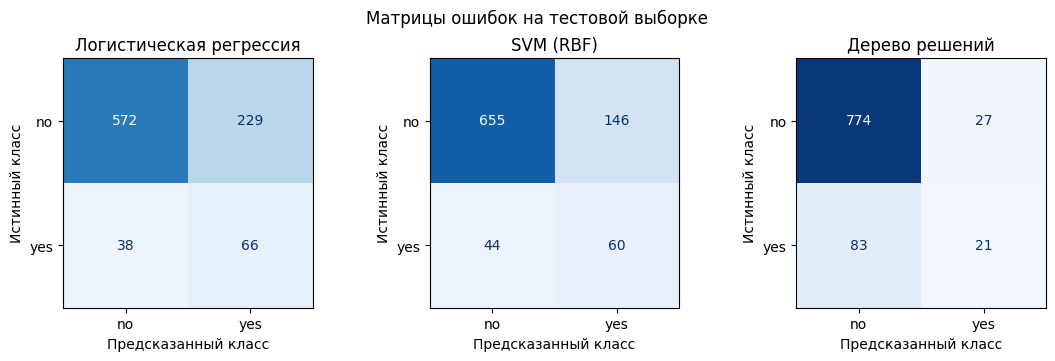

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout='constrained')

for ax, (name, predicted) in zip(axes, predictions.items()):
    matrix = ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=['no', 'yes'],
        cmap='Blues', colorbar=False, ax=ax,
    )
    matrix.im_.set_clim(0, y_test.value_counts().max())
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')

fig.suptitle('Матрицы ошибок на тестовой выборке')
plt.show()

## 6. Важность признаков в дереве решений

`feature_importances_` показывает долю суммарного взвешенного уменьшения неоднородности Джини, которое дали разбиения по признаку. Для категориального столбца складываем вклады всех его one-hot индикаторов. Нулевая важность означает, что обученное дерево не использовало этот признак в своих разбиениях.

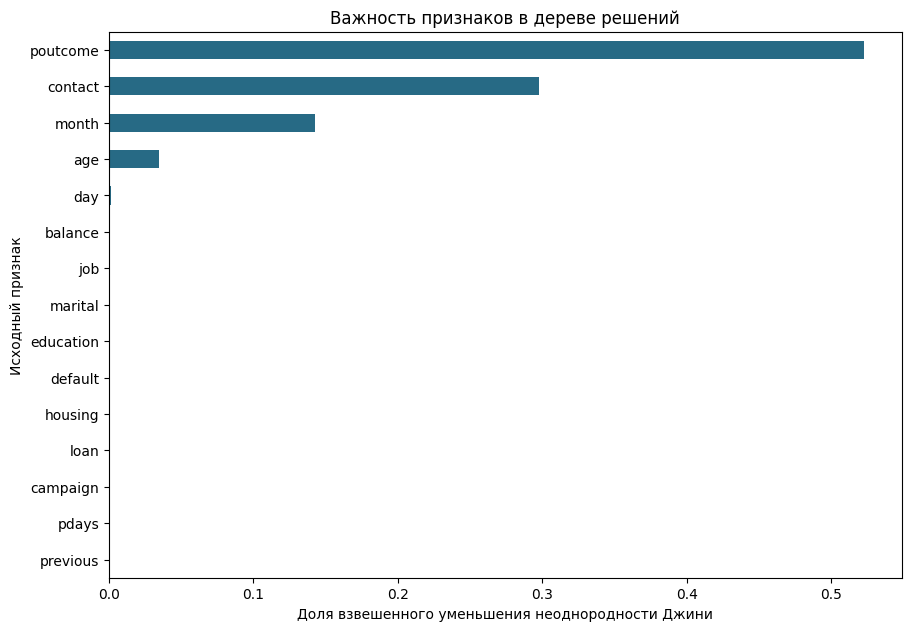

,Важность
poutcome,0.5227
contact,0.2979
month,0.1425
age,0.0347
day,0.0015
balance,0.0007


In [8]:
tree_pipeline = models['Дерево решений']
tree_preprocessor = tree_pipeline.named_steps['preprocessing']
tree = tree_pipeline.named_steps['model']
encoder = tree_preprocessor.named_transformers_['categorical']
encoded_columns = tree_preprocessor.get_feature_names_out().tolist()

original_columns = numeric_features + [
    feature
    for feature, categories in zip(categorical_features, encoder.categories_)
    for _ in categories
]
importance = (
    pd.Series(tree.feature_importances_, index=original_columns, name='Важность')
    .groupby(level=0).sum()
    .reindex(X.columns)
    .sort_values(ascending=False, kind='stable')
)

fig, ax = plt.subplots(figsize=(9, 6.2), layout='constrained')
importance.iloc[::-1].plot.barh(ax=ax, color='#276a85')
ax.set_xlabel('Доля взвешенного уменьшения неоднородности Джини')
ax.set_ylabel('Исходный признак')
ax.set_title('Важность признаков в дереве решений')
plt.show()

display(importance[importance > 0].round(4).to_frame())

## 7. Визуализация дерева решений

Для каждого внутреннего узла при выполнении условия идём в левую ветвь, иначе — в правую. Например, для one-hot признака условие `<= 0.5` означает отсутствие соответствующей категории. В узлах `samples` показывает долю обучающих объектов, а `value` — доли классов с учётом их весов.

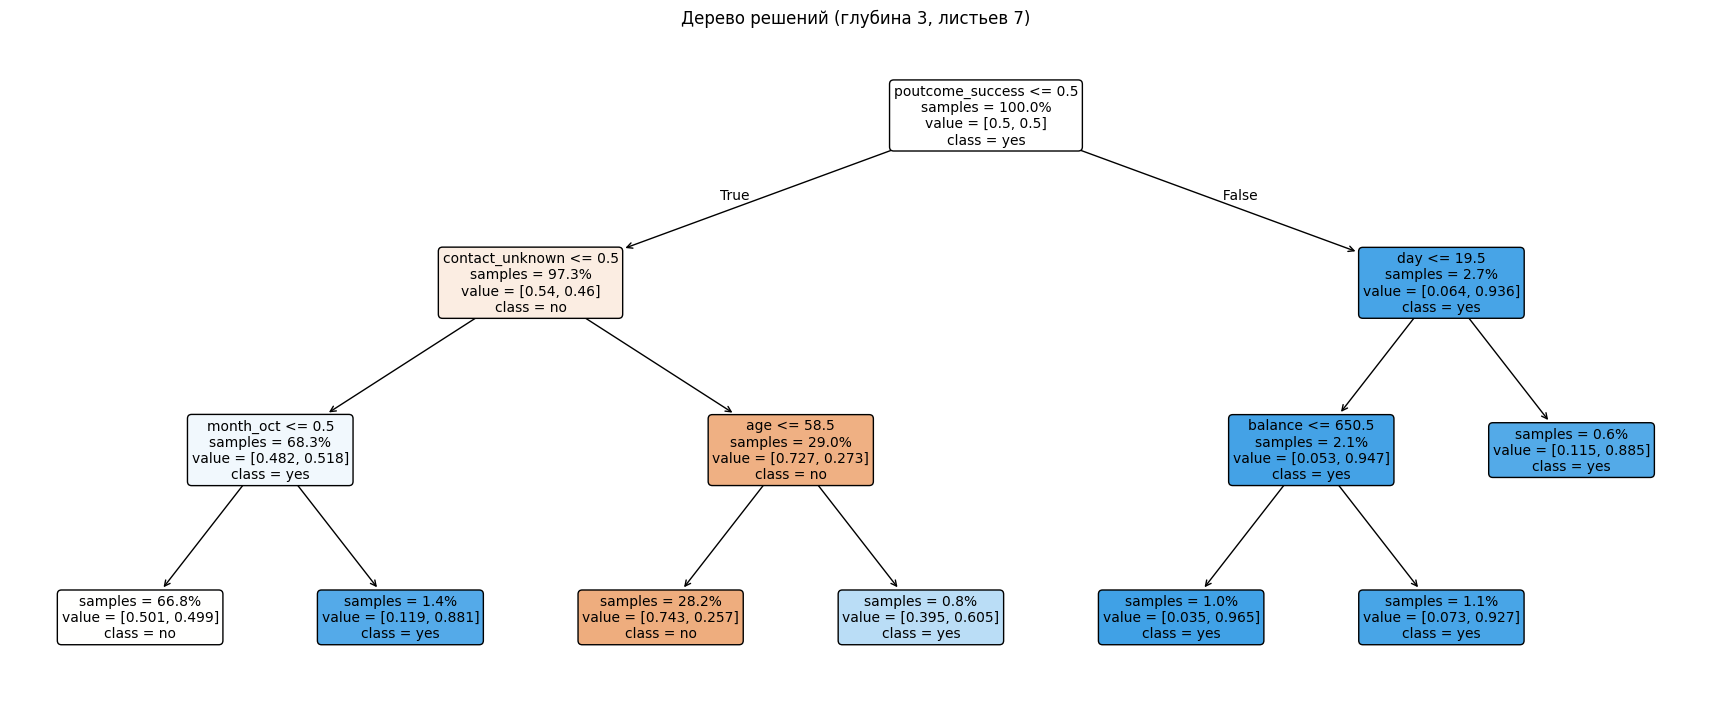

In [9]:
fig, ax = plt.subplots(figsize=(17, 7), layout='constrained')
plot_tree(
    tree,
    feature_names=encoded_columns,
    class_names=tree.classes_.tolist(),
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=10,
    ax=ax,
)
ax.set_title(f'Дерево решений (глубина {tree.get_depth()}, листьев {tree.get_n_leaves()})')
plt.show()

## Вывод

1. Из 4 521 записи 3 616 использовались для обучения и 905 для тестирования. Категориальные признаки закодированы на обучающей выборке. Длительность звонка исключена, чтобы прогноз можно было построить к его началу.
2. На тестовой выборке SVM с RBF-ядром получила наибольшие balanced accuracy (0,6973) и F1 для класса `yes` (0,3871). Она нашла 60 из 104 клиентов, открывших вклад. Логистическая регрессия нашла 66, при этом дала 229 ложных срабатываний против 146 у SVM. Дерево допустило 27 ложных срабатываний и обнаружило 21 положительный случай.
3. В дереве наибольший вклад дали результат предыдущей кампании (`poutcome`, 52,27%), канал контакта (`contact`, 29,79%) и месяц (`month`, 14,25%). Эти доли описывают разбиения обученного дерева. Сравнение моделей относится к выбранному тестовому разбиению.